# Random Forest Classifier

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Random Forest is an ensemble learning algorithm that constructs multiple decision trees and combines their predictions to improve classification accuracy and reduce overfitting.

In this notebook, a Random Forest classifier is trained using the PCA-transformed applicant dataset to predict loan default.

The objectives of this notebook are to:

- Train a Random Forest classifier.
- Predict applicant default status.
- Evaluate model performance.
- Analyze the importance of principal components.
- Compare the model with previously developed classifiers.

# Import Required Libraries

The following libraries are used for model development, evaluation, and visualization.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed training and testing datasets created during feature engineering are loaded for model development.

In [2]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Train Random Forest Model

A Random Forest classifier is trained using the training dataset.

The model combines multiple decision trees using bootstrap aggregation (bagging), improving robustness and reducing variance.

In [3]:
# ============================================================
# Train Random Forest
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


# Generate Predictions

The trained Random Forest model predicts both applicant class labels and the probability of default.

In [4]:
# ============================================================
# Predictions
# ============================================================

y_pred = rf_model.predict(X_test)

y_prob = rf_model.predict_proba(X_test)[:, 1]

# Model Evaluation

The Random Forest classifier is evaluated using multiple performance metrics:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

In [5]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.919142
1,Precision,0.100000
2,Recall,0.000201
3,F1 Score,0.000402
4,ROC AUC,0.729338


# Confusion Matrix

The confusion matrix summarizes the model's predictions by comparing predicted and actual loan default classes.

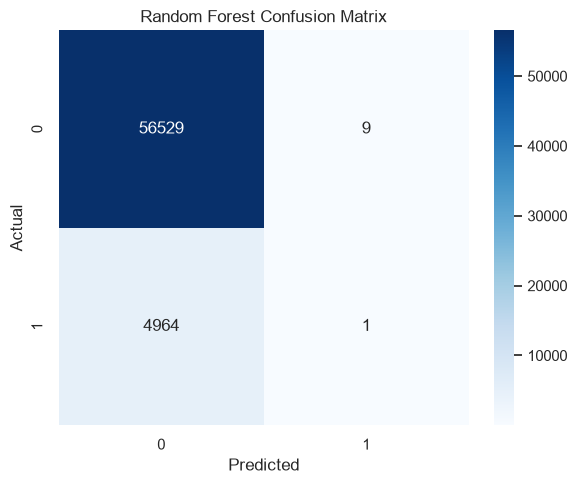

In [6]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.tight_layout()

plt.show()

# Classification Report

The classification report provides precision, recall, F1-score, and support for each class.

In [7]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.10      0.00      0.00      4965

    accuracy                           0.92     61503
   macro avg       0.51      0.50      0.48     61503
weighted avg       0.85      0.92      0.88     61503



# ROC Curve

The ROC Curve illustrates the model's ability to discriminate between default and non-default applicants across different classification thresholds.

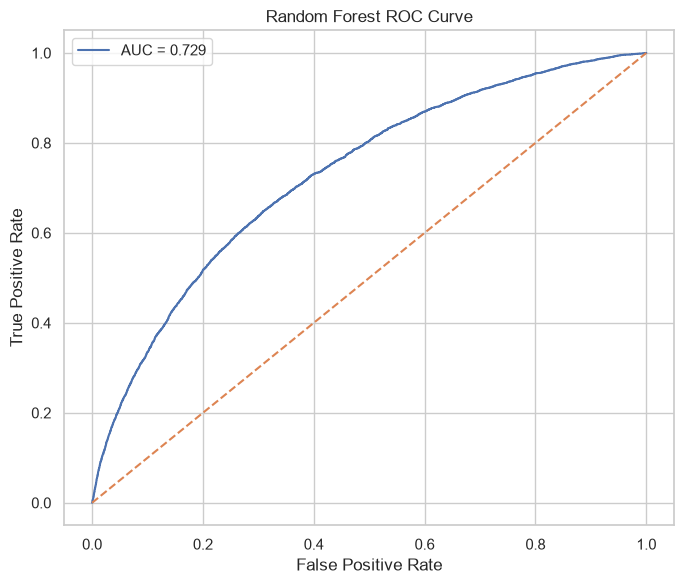

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot([0,1], [0,1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# Feature Importance

Random Forest estimates the contribution of each input feature based on the average reduction in impurity across all decision trees.

Since PCA components are used as predictors, the importance values indicate which principal components contribute most to the classification task.

In [9]:
feature_importance = (
    pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": rf_model.feature_importances_
    })
    .sort_values(
        by="Importance",
        ascending=False
    )
)

feature_importance.head(15)

,Feature,Importance
8,PC9,0.033889
17,PC18,0.027288
19,PC20,0.023791
2,PC3,0.021033
7,PC8,0.020084
1,PC2,0.017416
25,PC26,0.015256
28,PC29,0.014694
30,PC31,0.014682
24,PC25,0.012662


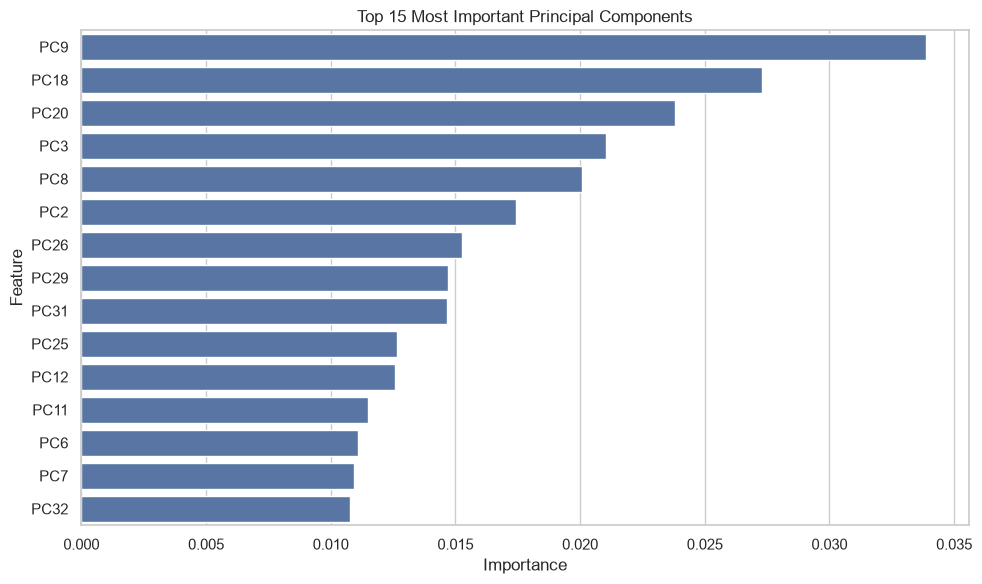

In [10]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Most Important Principal Components")

plt.tight_layout()

plt.show()

# Model Configuration

The Random Forest model was trained using the following hyperparameters:

- Number of Trees (`n_estimators`) = 200
- Maximum Tree Depth (`max_depth`) = 15
- Minimum Samples to Split = 10
- Random State = 42

These parameters were selected to balance predictive performance and model complexity while reducing the risk of overfitting.

# Save Trained Model

The trained Logistic Regression model is saved for future prediction, evaluation, and deployment.

In [12]:
# ============================================================
# Save Random Forest Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    rf_model,
    MODEL_DIR / "random_forest_model.pkl"
)

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


# Save Model Performance

The evaluation metrics of the Random Forest classifier are appended to the common model results file for comparison with the remaining machine learning models.

In [11]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["Random Forest"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,Random Forest,0.919142,0.1,0.000201,0.000402,0.729338,9,4964,1,56529


# Conclusion

The Random Forest classifier was successfully trained and evaluated using the PCA-transformed applicant dataset.

## Key Outcomes

- An ensemble learning model was developed for credit risk prediction.
- Performance was assessed using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- Feature importance analysis identified the principal components that contributed most to the model's predictions.
- The confusion matrix and ROC curve demonstrated the classifier's predictive capability.
- Performance metrics were saved for comparison with all other classification models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 11 – XGBoost Classifier**